# Pré-processamento e redução de dimensionalidade das CATs do Ceará

Este experimento investiga a seleção e a extração de características para a classificação de **Indica Óbito Acidente** em um cenário de **triagem e avaliação de gravidade no registro do acidente**. A classe positiva é **Sim**.

O recorte reúne CATs com UF do acidente informada como Ceará e data do acidente entre janeiro e junho de 2026. Uma linha representa um registro de CAT. As proporções de óbito descrevem os registros disponíveis e dependem da cobertura dessa base.

A sequência começa pela inspeção e preparação dos dados, passa pela divisão entre treino e teste e pela codificação das categorias, e termina com a comparação das representações produzidas pelos filtros, Wrapper, árvore e PCA.

**Escopo do experimento.** As técnicas de redução avaliam cinco entradas categóricas relevantes para triagem de gravidade — `Tipo do Acidente`, `Agente  Causador  Acidente`, `Parte Corpo Atingida`, `Natureza da Lesão` e `Sexo`. O one-hot transforma suas categorias em indicadores binários. A quantidade de indicadores depende das categorias encontradas no treino.

Execute as células na ordem, com a pasta `CD_CAT_2026` como diretório de trabalho. As interpretações numéricas registradas ao longo do texto se referem à base atual e à divisão com `random_state=42`.

## 1. Bibliotecas

Usaremos `pandas` e `numpy` para preparar tabelas e calcular estatísticas, `matplotlib` para os gráficos e `scikit-learn` para a divisão dos dados, a codificação e os métodos de redução. A função `codificar_agentes` utiliza o dicionário de agentes causadores disponível no projeto.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest,
    chi2,
    mutual_info_classif,
    SequentialFeatureSelector,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA

from scripts.agente_causador import codificar_agentes

## 2. Carregamento e recorte da base

Os seis arquivos mensais de janeiro a junho estão em `datasets/CAT_2026`. A leitura usa separador `;` e codificação `latin-1`. Os códigos CBO e CNAE são lidos como texto para preservar seus zeros à esquerda.

Depois da concatenação, selecionamos a UF do acidente Ceará e as datas de acidente entre 1º de janeiro e 30 de junho de 2026. O período é definido pela data do acidente registrada em cada linha. Datas inválidas são convertidas em valores ausentes e ficam fora desse recorte.

A inspeção inicial apresenta exemplos, dimensões e tipos das colunas.

In [2]:
datasets = {
    "janeiro": "datasets/CAT_2026/D.SDA.PDA.005.CAT.202601.csv",
    "fevereiro": "datasets/CAT_2026/D.SDA.PDA.005.CAT.202602.csv",
    "março": "datasets/CAT_2026/D.SDA.PDA.005.CAT.202603.csv",
    "abril": "datasets/CAT_2026/D.SDA.PDA.005.CAT.202604.csv",
    "maio": "datasets/CAT_2026/D.SDA.PDA.005.CAT.202605.csv",
    "junho": "datasets/CAT_2026/D.SDA.PDA.005.CAT.202606.csv"
}

for key in datasets:
    datasets[key] = pd.read_csv(
        datasets[key],
        encoding="latin-1",
        sep=";",
        dtype={
            "CBO": "string",
            "CNAE2.0 Empregador": "string",
        },
    )

df_total = pd.concat(datasets.values(), ignore_index=True)
uf = df_total["UF  Munic.  Acidente"].str.strip()
df_ceara = df_total.loc[uf.eq("Ceará")].copy()

data_acidente = pd.to_datetime(
    df_ceara["Data Acidente"].str.strip(),
    format="%d/%m/%Y",
    errors="coerce",
)

no_semestre = data_acidente.between("2026-01-01", "2026-06-30")
df_ceara = df_ceara.loc[no_semestre].copy()

display(df_ceara.head())
print("Dimensão da base:", df_ceara.shape)

print("\nTipos das colunas:")
display(df_ceara.dtypes.to_frame("dtype"))

,Agente Causador Acidente,Data Acidente,CBO,CBO.1,CID-10,CID-10.1,CNAE2.0 Empregador,CNAE2.0 Empregador.1,Emitente CAT,Espécie do benefício,...,Tipo do Acidente,UF Munic. Acidente,UF Munic. Empregador,Data Afastamento,Data Despacho Benefício,Data Acidente.1,Data Nascimento,Data Emissão CAT,Tipo de Empregador,CNPJ/CEI Empregador
16,Chao - Superficie Ut,16/01/2026,514325,{ñ class},S836,S83.6 Entorse Disten,7312,Agenciamento de Espa,Empregador,Pa,...,Típico,Ceará,Distrito Federal,15/01/2026,00/00/0000,16/01/2026,06/10/2000,19/01/2026,Cnpj/Cgc,5777957000162
31,"Madeira (Toro, Madei",12/01/2026,717020,717020-Servente de O,S701,S70.1 Contusao da Co,4120,Construcao de Edific,Empregador,Pa,...,Típico,Ceará,Distrito Federal,12/01/2026,00/00/0000,12/01/2026,10/03/1999,21/01/2026,Cnpj/Cgc,7044248000101
46,Rua e Estrada - Supe,05/01/2026,519110,519110-Motociclista,T149,T14.9 Traum Ne,5320,Atividades de Malote,Empregador,Pa,...,Trajeto,Ceará,Distrito Federal,05/01/2026,00/00/0000,05/01/2026,18/06/1984,22/01/2026,Cnpj/Cgc,51457007000178
87,"Andaime, Plataforma",07/01/2026,715615,715615-Eletricista I,S400,S40.0 Contusao do Om,0000,{ñ class},Empregador,Pa,...,Típico,Ceará,Zerado,08/01/2026,00/00/0000,07/01/2026,03/07/2001,09/01/2026,Cnpj/Cgc,900230656179
160,Agente Infeccioso ou,10/01/2026,322205,322205-Tec. de Enfer,Z209,Z20.9 Contato Exposi,8660,Atividades de Apoio,Empregador,Pa,...,Típico,Ceará,Distrito Federal,10/01/2026,00/00/0000,10/01/2026,20/02/1990,26/01/2026,Cnpj/Cgc,15126437000143


Dimensão da base: (8849, 27)

Tipos das colunas:


,dtype
Agente Causador Acidente,str
Data Acidente,str
CBO,string
CBO.1,string
CID-10,str
CID-10.1,str
CNAE2.0 Empregador,string
CNAE2.0 Empregador.1,string
Emitente CAT,str
Espécie do benefício,str


## 3. Perfil inicial dos atributos

O perfil apresenta o tipo computacional, a quantidade e o percentual de ausentes e o número de valores distintos de cada coluna. Nesta primeira inspeção, o marcador `{ñ class}` é reconhecido como ausência.

Esse diagnóstico ajuda a localizar campos constantes, descrições incompletas e identificadores. Códigos de ausência próprios de determinados campos, como `0000` na CNAE, serão tratados adiante.

In [3]:
base_perfil = df_ceara.replace(r"^\s*\{ñ class\}\s*$", pd.NA, regex=True)
ausentes = base_perfil.isna()

perfil = pd.DataFrame({
    "tipo": df_ceara.dtypes.astype(str),
    "ausentes": ausentes.sum(),
    "percentual_ausentes": (100 * ausentes.mean()).round(2),
    "valores_unicos": base_perfil.nunique(dropna=True),
})

display(perfil)

,tipo,ausentes,percentual_ausentes,valores_unicos
Agente Causador Acidente,str,183,2.07,196
Data Acidente,str,0,0.00,181
CBO,string,0,0.00,621
CBO.1,string,1380,15.59,527
CID-10,str,0,0.00,922
CID-10.1,str,17,0.19,919
CNAE2.0 Empregador,string,0,0.00,303
CNAE2.0 Empregador.1,string,279,3.15,187
Emitente CAT,str,12,0.14,5
Espécie do benefício,str,0,0.00,1


## 4. Registros duplicados

Verificamos repetições exatas considerando os 27 campos originais. `duplicated(keep=False)` marca todas as linhas envolvidas nas repetições, incluindo a primeira ocorrência de cada combinação.

A interpretação de duplicatas depende da unidade de registro. Sem um identificador único do acidente, a igualdade entre linhas é uma evidência de repetição dos dados disponíveis.

In [4]:
duplicadas = df_ceara.duplicated(keep=False)

print("Linhas envolvidas em duplicatas exatas:", duplicadas.sum())

display(df_ceara.loc[duplicadas].head(5))

Linhas envolvidas em duplicatas exatas: 3296


,Agente Causador Acidente,Data Acidente,CBO,CBO.1,CID-10,CID-10.1,CNAE2.0 Empregador,CNAE2.0 Empregador.1,Emitente CAT,Espécie do benefício,...,Tipo do Acidente,UF Munic. Acidente,UF Munic. Empregador,Data Afastamento,Data Despacho Benefício,Data Acidente.1,Data Nascimento,Data Emissão CAT,Tipo de Empregador,CNPJ/CEI Empregador
119200,{ñ class},22/01/2026,111220,111220-Secretário -,F332,F33.2 Trans Depr Rec,8411,Administracao Public,Segurado/Dependente,Pa,...,Doença,Ceará,Distrito Federal,07/04/2024,00/00/0000,22/01/2026,02/03/1965,01/03/2026,Cnpj/Cgc,530352000159
119202,"Esforco Excessivo, N",10/02/2026,322205,322205-Tec. de Enfer,M545,M54.5 Dor Lombar Bai,9430,Atividades de Associ,Segurado/Dependente,Pa,...,Doença,Ceará,Distrito Federal,09/02/2026,00/00/0000,10/02/2026,20/06/1981,01/03/2026,Cnpj/Cgc,37318510000111
119777,{ñ class},22/01/2026,111220,111220-Secretário -,F332,F33.2 Trans Depr Rec,8411,Administracao Public,Segurado/Dependente,Pa,...,Doença,Ceará,Distrito Federal,07/04/2024,00/00/0000,22/01/2026,02/03/1965,01/03/2026,Cnpj/Cgc,530352000159
177010,"Esforco Excessivo, N",10/02/2026,322205,322205-Tec. de Enfer,M545,M54.5 Dor Lombar Bai,9430,Atividades de Associ,Segurado/Dependente,Pa,...,Doença,Ceará,Distrito Federal,09/02/2026,00/00/0000,10/02/2026,20/06/1981,01/03/2026,Cnpj/Cgc,37318510000111
191113,"Mesa, Carteira, Exce",20/03/2026,413225,413225-Escriturário,M771,M77.1 Epicondilite L,6423,Caixas Economicas,Segurado/Dependente,Pa,...,Doença,Ceará,Distrito Federal,20/03/2026,00/00/0000,20/03/2026,23/10/1980,01/04/2026,Cnpj/Cgc,360305000104


### 4.1 Decisão de tratamento

Neste experimento, mantemos uma ocorrência de cada combinação idêntica dos 27 campos, antes de transformar os atributos.

Na base atual, 3.296 linhas participam de duplicatas. A remoção das ocorrências adicionais elimina 1.648 linhas e reduz a base de 8.849 para 7.201 registros. A diferença entre esses números decorre de preservar uma ocorrência de cada combinação.

In [5]:
df_ceara = df_ceara.drop_duplicates().reset_index(drop=True)

print("Dimensão após remover duplicatas:", df_ceara.shape)

Dimensão após remover duplicatas: (7201, 27)


## 5. Tratamento de ausências e códigos

Substituímos `{ñ class}` por `pd.NA`. No agente causador, as ausências recebem a categoria `Desconhecido`. A tabela apresentada nesta etapa registra as ausências antes desse preenchimento.

O tratamento permite conservar os registros e explicitar a falta de informação. As cinco entradas usadas no one-hot terão espaços removidos e valores vazios preenchidos antes da codificação.

In [6]:
marcador_ausente = r"^\s*\{ñ class\}\s*$"
coluna_agente = "Agente  Causador  Acidente"

df_ceara = df_ceara.replace(marcador_ausente, pd.NA, regex=True)

ausentes = pd.DataFrame({
    "quantidade": df_ceara.isna().sum(),
    "percentual": (100 * df_ceara.isna().mean()).round(2),
})

df_ceara[coluna_agente] = df_ceara[coluna_agente].fillna("Desconhecido")

display(
    ausentes.loc[ausentes["quantidade"] > 0]
    .sort_values("percentual", ascending=False)
)

,quantidade,percentual
CBO.1,1118,15.53
Origem de Cadastramento CAT,664,9.22
CNAE2.0 Empregador.1,237,3.29
Agente Causador Acidente,139,1.93
CID-10.1,13,0.18
Emitente CAT,9,0.12
Tipo de Empregador,3,0.04
Filiação Segurado,1,0.01


### 5.1 Agentes causadores com descrições truncadas

A descrição abreviada pode ser compatível com mais de um código. Por exemplo, `Puncao, Ponteiro, Va` aparece como prefixo de descrições de ferramenta manual e ferramenta com força motriz.

A função `codificar_agentes` associa o texto ao dicionário quando encontra uma correspondência única. Os casos ausentes, ambíguos ou sem correspondência recebem `Desconhecido` na entrada do modelo. A variável `resultado_agente` conserva a situação de cada associação para inspeção.

Na execução de referência, 6.538 registros tiveram associação única. Os demais 663 registros reuniram 139 ausências, 131 ambiguidades e 393 descrições sem correspondência.

In [7]:
resultado_agente = codificar_agentes(df_ceara[coluna_agente])

df_ceara[coluna_agente] = resultado_agente["codigo"].fillna("Desconhecido")

display(resultado_agente["situacao"].value_counts().to_frame("registros"))

,registros
situacao,
associado,6538
sem correspondência,393
ausente,139
ambíguo,131


### 5.2 Códigos CBO e CNAE sem informação

Os códigos `000000` na CBO e `0000` na CNAE são tratados como desconhecidos. Também removemos espaços e tratamos códigos vazios.

Esses campos permanecem na tabela de candidatos preparada nesta etapa. A comparação de redução apresentada neste notebook usa as três entradas categóricas definidas na seção 11.

In [8]:
codigos_nao_informados = {
    "CBO": "000000",
    "CNAE2.0 Empregador": "0000",
}

for coluna, marcador in codigos_nao_informados.items():
    df_ceara[coluna] = (
        df_ceara[coluna]
        .str.strip()
        .replace(["", marcador], pd.NA)
        .fillna("Desconhecido")
    )

display(df_ceara[["CBO", "CNAE2.0 Empregador"]].head())

,CBO,CNAE2.0 Empregador
0,514325,7312
1,717020,4120
2,519110,5320
3,715615,Desconhecido
4,322205,8660


## 6. Definição dos atributos candidatos

A primeira revisão considera a função de cada campo, a quantidade de informação disponível e a possibilidade de utilizá-lo no momento da previsão.

### 6.1 Identificador do empregador

`CNPJ/CEI Empregador` identifica o empregador e apresenta alta cardinalidade. Sua exclusão é uma decisão de escopo deste experimento. O número de identificadores distintos ajuda a caracterizar o campo.

In [9]:
print("Número de linhas:", len(df_ceara))
print("Número de IDs distintos:", df_ceara["CNPJ/CEI Empregador"].nunique())

display(df_ceara[["CNPJ/CEI Empregador"]].head())


Número de linhas: 7201
Número de IDs distintos: 2770


,CNPJ/CEI Empregador
0,5777957000162
1,7044248000101
2,51457007000178
3,900230656179
4,15126437000143


### 6.2 Constantes e informação administrativa

A contagem de valores distintos inclui ausências. Na base atual, `UF  Munic.  Acidente` contém Ceará, `Espécie do benefício` contém Pa e `Data Despacho Benefício` apresenta um único marcador de data inválida.

`Origem de Cadastramento CAT` contém Internet e ausências. Essa ausência varia entre registros e poderia ser investigada como característica. Aqui, o campo é excluído por decisão de escopo administrativo.

In [10]:
n_unicos = df_ceara.nunique(dropna=False).sort_values()

display(
    n_unicos.to_frame("quantidade_valores_distintos").head(10)
)

,quantidade_valores_distintos
Espécie do benefício,1
UF Munic. Acidente,1
Data Despacho Benefício,1
Indica Óbito Acidente,2
Origem de Cadastramento CAT,2
Tipo do Acidente,3
Sexo,3
Filiação Segurado,4
Tipo de Empregador,4
Emitente CAT,6


In [11]:
print(df_ceara["Origem de Cadastramento CAT"].unique())

<ArrowStringArray>
['Internet            ', nan]
Length: 2, dtype: str


### 6.3 Data sem informação válida

Todas as linhas de `Data Despacho Benefício` apresentam `00/00/0000`. Por isso, o campo é retirado da tabela de candidatos.

In [12]:
display(df_ceara[["Data Despacho Benefício"]].head())

,Data Despacho Benefício
0,00/00/0000
1,00/00/0000
2,00/00/0000
3,00/00/0000
4,00/00/0000


### 6.4 Informações clínicas e momento da previsão (cenário de triagem)

O alvo deste experimento é `Indica Óbito Acidente`. Adotamos o cenário de **triagem e avaliação de gravidade no registro do acidente**: pressupõe-se que o relato inicial já informa o tipo do acidente, o agente causador, a parte do corpo atingida, a natureza da lesão e o sexo do trabalhador.

Por outro lado, `CID-10` e sua descrição (`CID-10.1`) permanecem fora da tabela de candidatos por representarem codificação diagnóstica detalhada que frequentemente só é consolidada posteriormente ao atendimento inicial. Já `Tipo de Empregador` também não entra na modelagem por ser quase constante neste recorte (`Cnpj/Cgc` responde por 99,90% das linhas e por todos os 27 óbitos).

### 6.5 Código e descrição do mesmo atributo

Os pares `CBO`/`CBO.1` e `CNAE2.0 Empregador`/`CNAE2.0 Empregador.1` representam códigos e suas descrições. Mantemos os códigos e retiramos as descrições correspondentes da tabela de candidatos.

### 6.6 Remoção inicial

| Campo ou grupo | Decisão adotada |
|---|---|
| CNPJ/CEI Empregador | Excluir o identificador do empregador |
| UF do acidente e espécie do benefício | Excluir campos constantes no recorte |
| Origem de Cadastramento CAT | Excluir por escopo administrativo |
| Data Despacho Benefício | Excluir o campo preenchido por data inválida |
| CID-10 e CID-10.1 | Excluir considerando o cenário de disponibilidade do diagnóstico |
| CBO.1 e CNAE2.0 Empregador.1 | Excluir descrições associadas aos códigos mantidos |

Essa etapa reduz a tabela de 27 para 18 colunas, incluindo o alvo. A seleção das cinco entradas de triagem do experimento será explicitada antes do one-hot.

In [13]:
colunas_nao_modelagem = [
    "CNPJ/CEI Empregador",
    "UF  Munic.  Acidente",
    "Espécie do benefício",
    "Origem de Cadastramento CAT",
    "Data Despacho Benefício",
    "CID-10",
    "CID-10.1",
    "CBO.1",
    "CNAE2.0 Empregador.1",
]

df_modelo = df_ceara.drop(columns=colunas_nao_modelagem).copy()

print("Dimensão original:", df_ceara.shape)
print("Dimensão após remoção inicial:", df_modelo.shape)


Dimensão original: (7201, 27)
Dimensão após remoção inicial: (7201, 18)


## 7. Separação entre preditores e alvo

`X` reúne os 17 atributos candidatos. `y` contém `Indica Óbito Acidente`, com os rótulos Sim e Não. Removemos espaços dos rótulos para tornar a identificação das classes consistente.

In [14]:
X = df_modelo.drop(columns="Indica Óbito Acidente")
y = df_modelo["Indica Óbito Acidente"].str.strip()

print("X", X.shape)
print("y", y.shape)

X (7201, 17)
y (7201,)


## 8. Distribuição do alvo

A distribuição das classes orienta a divisão estratificada e a escolha das métricas. O diagnóstico abaixo considera os 7.201 registros após o tratamento das duplicatas.

,quantidade,percentual
Indica Óbito Acidente,,
Não,7174,99.63
Sim,27,0.37


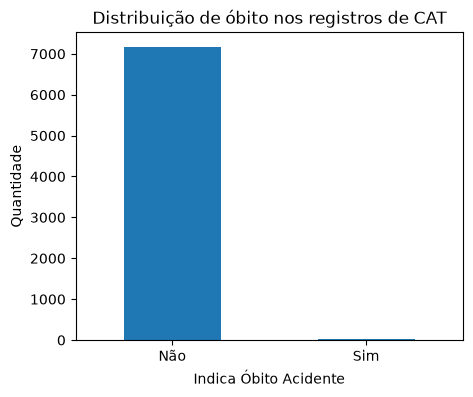

In [15]:
contagem = y.value_counts()
percentual = (100 * y.value_counts(normalize=True)).round(2)

display(pd.DataFrame({
    "quantidade": contagem,
    "percentual": percentual
}))

plt.figure(figsize=(5,4))
y.value_counts().plot(kind="bar")
plt.ylabel("Quantidade")
plt.title("Distribuição de óbito nos registros de CAT")
plt.xticks(rotation=0)
plt.show()

### 8.1 Interpretação do desbalanceamento

A base contém 27 registros com óbito, aproximadamente 0,37% do total. A classe Sim é muito menos frequente que a classe Não. Um modelo que classificasse todos os registros como Não teria acurácia de aproximadamente 99,63% e recall de Sim igual a zero.

Por isso, a avaliação preditiva deve considerar **average precision**, que resume a relação entre precisão e recall ao variar o limiar, e **recall de Sim**, que mede a fração dos óbitos identificados. A precisão informa a fração de alertas de óbito que corresponde a registros com óbito.

A divisão será estratificada. Eventual reamostragem deverá ocorrer dentro do treino de cada partição de validação.

## 9. Divisão entre treino e teste

Usamos uma divisão aleatória estratificada, com 80% dos registros no treino, 20% no teste e `random_state=42`. A estratificação preserva aproximadamente a proporção das classes.

Na base atual, o treino contém 5.760 registros e 22 óbitos. O teste contém 1.441 registros e 5 óbitos. Uma avaliação temporal exigiria definir as partições pelas datas.

As explorações orientadas pelo alvo apresentadas a seguir usam o treino. Os parâmetros do one-hot, dos seletores, da padronização e do PCA também serão ajustados no treino e aplicados ao teste.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

print("\nProporção no treino:")
print(y_train.value_counts(normalize=True).round(3))

print("\nProporção no teste:")
print(y_test.value_counts(normalize=True).round(3))


Treino: (5760, 17)
Teste: (1441, 17)

Proporção no treino:
Indica Óbito Acidente
Não    0.996
Sim    0.004
Name: proportion, dtype: float64

Proporção no teste:
Indica Óbito Acidente
Não    0.997
Sim    0.003
Name: proportion, dtype: float64


## 10. Exploração dos óbitos no treino

### 10.1 Tipo do acidente

A tabela reúne a quantidade de registros, a quantidade de óbitos e o percentual com óbito em cada tipo de acidente. O denominador do percentual é o total de registros daquele tipo no treino.

In [17]:
cats = pd.DataFrame({
    "tipo": X_train["Tipo do Acidente"].str.strip(),
    "obito": y_train.eq("Sim"),
})

resumo = cats.groupby("tipo")["obito"].agg(
    total_cats="size",
    obitos="sum",
)

resumo["percentual_com_obito"] = (
    100 * resumo["obitos"] / resumo["total_cats"]
).round(2)

display(resumo.sort_values("percentual_com_obito", ascending=False))

,total_cats,obitos,percentual_com_obito
tipo,,,
Trajeto,1373,12,0.87
Típico,3982,10,0.25
Doença,405,0,0.00


Na execução de referência, os acidentes de trajeto somam 12 óbitos em 1.373 registros, aproximadamente 0,87%. A proporção geral do treino é 22 em 5.760, aproximadamente 0,38%. Essa diferença motiva investigar a associação entre tipo do acidente e óbito nos métodos de seleção.

### 10.2 Agente causador

Recuperamos os nomes dos agentes pelo dicionário e mostramos as categorias que apresentam pelo menos um óbito no treino.

Percentuais calculados com poucas ocorrências podem variar bastante com um único registro adicional. A interpretação considera conjuntamente a descrição, a quantidade de registros e a quantidade de óbitos.

In [18]:
agentes = pd.read_csv(
    "datasets/agente_causador_acidente_trabalho.csv",
    dtype={"codigo": "string"},
).set_index("codigo")["descricao"]

resumo_agente = (
    cats.assign(agente=X_train["Agente  Causador  Acidente"])
    .groupby("agente")["obito"]
    .agg(total_cats="size", obitos="sum")
)

resumo_agente["percentual_com_obito"] = (
    100 * resumo_agente["obitos"] / resumo_agente["total_cats"]
).round(2)

resumo_agente.insert(
    0, "descricao", resumo_agente.index.map(agentes).fillna("Desconhecido")
)

display(
    resumo_agente.loc[resumo_agente["obitos"] > 0]
    .sort_values(["obitos", "total_cats"], ascending=False)
)

,descricao,total_cats,obitos,percentual_com_obito
agente,,,,
303075900,"Veículo, NIC",336,4,1.19
303075200,"Motocicleta, motoneta",355,3,0.85
303075250,Veículo rodoviário motorizado,309,3,0.97
302010200,Rua e estrada - superfície utilizada para sust...,288,2,0.69
309500000,Agente do acidente inexistente,92,2,2.17
Desconhecido,Desconhecido,525,1,0.19
309000000,"Agente do acidente, NIC",461,1,0.22
302010550,Chão - superfície utilizada para sustentar pes...,338,1,0.30
302010350,Escada permanente cujos degraus permitem apoio...,309,1,0.32


## 11. Entradas categóricas e one-hot

O experimento usa cinco atributos categóricos ligados à triagem de gravidade: `Tipo do Acidente`, `Agente  Causador  Acidente`, `Parte Corpo Atingida`, `Natureza da Lesão` e `Sexo`. Essa escolha substitui `Tipo de Empregador` (quase constante, com 99,90% de `Cnpj/Cgc`) por atributos diretamente relacionados à severidade do evento.

O one-hot cria um indicador por categoria. Por exemplo, `Parte Corpo Atingida_Cranio (Inclusive En` vale 1 quando o crânio foi atingido e 0 nos demais casos. Os códigos de agente são tratados como categorias nominais.

### 11.1 Limpeza e codificação

Removemos espaços, substituímos textos vazios e preenchemos ausências com `Desconhecido`. O encoder aprende as categorias no treino. Com `handle_unknown="ignore"`, uma categoria encontrada apenas no teste gera zeros no bloco de indicadores daquele atributo.

In [19]:
colunas_categoricas = [
    "Tipo do Acidente",
    "Agente  Causador  Acidente",
    "Parte Corpo Atingida",
    "Natureza da Lesão",
    "Sexo",
]

X_train_cat = X_train[colunas_categoricas].copy()
X_test_cat = X_test[colunas_categoricas].copy()

for base in (X_train_cat, X_test_cat):
    for coluna in colunas_categoricas:
        base[coluna] = (
            base[coluna]
            .astype("string")
            .str.strip()
            .replace("", pd.NA)
            .fillna("Desconhecido")
        )

encoder = OneHotEncoder(handle_unknown="ignore")

X_train_ohe = encoder.fit_transform(X_train_cat)
X_test_ohe = encoder.transform(X_test_cat)

print("Treino codificado:", X_train_ohe.shape)
print("Teste codificado:", X_test_ohe.shape)
print("Primeiras colunas:", encoder.get_feature_names_out()[:10])

Treino codificado: (5760, 228)
Teste codificado: (1441, 228)
Primeiras colunas: ['Tipo do Acidente_Doença' 'Tipo do Acidente_Trajeto'
 'Tipo do Acidente_Típico' 'Agente  Causador  Acidente_302010200'
 'Agente  Causador  Acidente_302010250'
 'Agente  Causador  Acidente_302010300'
 'Agente  Causador  Acidente_302010350'
 'Agente  Causador  Acidente_302010400'
 'Agente  Causador  Acidente_302010450'
 'Agente  Causador  Acidente_302010500']


### 11.2 Matriz numérica e parâmetros dos experimentos

As cinco entradas categóricas expandidas em *one-hot* geram uma matriz binária densa de fácil inspeção tabular.

Definimos **50 indicadores para cada filtro supervisionado** e **8 para o Wrapper**. A árvore selecionará os indicadores que efetivamente utilizar e o PCA calculará a quantidade de componentes necessária para preservar 90% da variância.

A codificação do alvo numérico será Sim = 1 e Não = 0.

In [20]:
# Recuperamos os nomes dos indicadores produzidos pelo one-hot.
nomes_indicadores = pd.Index(
    encoder.get_feature_names_out(),
    name="indicador",
)

# Para esta matriz binária compacta, podemos
# trabalhar com DataFrames densos, seguindo a organização da aula.
X_train_num = pd.DataFrame(
    X_train_ohe.toarray(),
    columns=nomes_indicadores,
    index=X_train_cat.index,
)

X_test_num = pd.DataFrame(
    X_test_ohe.toarray(),
    columns=nomes_indicadores,
    index=X_test_cat.index,
)

# Sim será a classe positiva nas técnicas que usam o alvo.
y_treino = (
    y_train.loc[X_train_num.index]
    .str.strip()
    .map({"Não": 0, "Sim": 1})
)

k_filtros = 50
k_wrapper = 8

print("Treino", X_train_num.shape)
print("Teste", X_test_num.shape)
print("Óbitos no treino", y_treino.sum())

Treino (5760, 228)
Teste (1441, 228)
Óbitos no treino 22


# Parte I — Métodos filtro

Os filtros avaliam propriedades dos indicadores ou sua associação individual com o alvo. Primeiro removemos constantes. Depois, qui-quadrado e informação mútua avaliam a mesma base resultante.

## 12. Variância

Para um indicador binário com frequência `p`, a variância populacional é `p × (1 − p)`. A variância zero identifica uma coluna que assume o mesmo valor em todos os registros do treino.

Usamos `ddof=0` para calcular a mesma definição de variância adotada pelo `VarianceThreshold`.

In [21]:
# ddof=0 usa a mesma definição de variância do VarianceThreshold.
variancias = X_train_num.var(ddof=0).sort_values()

display(variancias.to_frame("variancia"))

,variancia
indicador,
Agente Causador Acidente_303075400,0.000174
Agente Causador Acidente_305040250,0.000174
Agente Causador Acidente_303035300,0.000174
Agente Causador Acidente_303015550,0.000174
Agente Causador Acidente_303055200,0.000174
...,...
Parte Corpo Atingida_Dedo,0.155998
Tipo do Acidente_Trajeto,0.181549
Tipo do Acidente_Típico,0.213397


### 12.1 Aplicação do filtro

O limiar é zero. Indicadores raros continuam elegíveis quando apresentam alguma variação no treino. A base resultante será compartilhada pelos demais métodos.

In [22]:
filtro_var = VarianceThreshold(threshold=0.0)
filtro_var.fit(X_train_num)

mantidos_var = X_train_num.columns[
    filtro_var.get_support()
].tolist()

removidos_var = X_train_num.columns[
    ~filtro_var.get_support()
].tolist()

print("Quantidade removida por variância zero", len(removidos_var))

for indicador in removidos_var:
    print("✗", indicador)

# Esta será a base comum dos métodos seguintes.
X_train_base = X_train_num[mantidos_var].copy()
X_test_base = X_test_num[mantidos_var].copy()

print("Indicadores restantes", X_train_base.shape[1])

Quantidade removida por variância zero 0
Indicadores restantes 228


O filtro de variância zero verifica se algum indicador permanece constante no treino após a codificação *one-hot*. Todos os indicadores com variância positiva seguem para os métodos seguintes.

## 13. Qui-quadrado

O qui-quadrado mede a associação entre cada indicador e o alvo. Escores maiores indicam maior diferença entre as contagens observadas e as esperadas sob independência. Os indicadores binários atendem ao requisito de valores não negativos.

Selecionamos os 50 maiores escores. A tabela apresenta também ocorrências, óbitos e p-valores. As contagens pequenas de várias categorias limitam a interpretação da aproximação usada nos p-valores. O critério de seleção adotado é a posição no ranking.

In [23]:
sel_chi2 = SelectKBest(score_func=chi2, k=k_filtros)
sel_chi2.fit(X_train_base, y_treino)

res_chi2 = pd.DataFrame({
    "indicador": X_train_base.columns,
    "chi2_score": sel_chi2.scores_,
    "p_value": sel_chi2.pvalues_,
    "ocorrencias": X_train_base.sum().to_numpy().astype(int),
    "obitos": (
        X_train_base.loc[y_treino.eq(1)]
        .sum()
        .to_numpy()
        .astype(int)
    ),
    "selecionado": sel_chi2.get_support(),
}).sort_values("chi2_score", ascending=False)

display(res_chi2)

,indicador,chi2_score,p_value,ocorrencias,obitos,selecionado
174,Parte Corpo Atingida_Cranio (Inclusive En,293.285511,9.565040e-66,31,6,True
219,Natureza da Lesão_Lesoes Multiplas,108.999176,1.623533e-25,105,7,True
130,Agente Causador Acidente_305068300,85.611173,2.190344e-20,3,1,True
159,Parte Corpo Atingida_Abdome (Inclusive Or,61.751513,3.896520e-15,16,2,True
204,Natureza da Lesão_Concussao Cerebral,48.625749,3.097753e-12,20,2,True
...,...,...,...,...,...,...
114,Agente Causador Acidente_305040250,0.003834,9.506265e-01,1,0,False
117,Agente Causador Acidente_305040650,0.003834,9.506265e-01,1,0,False
118,Agente Causador Acidente_305040900,0.003834,9.506265e-01,1,0,False
129,Agente Causador Acidente_305064600,0.003834,9.506265e-01,1,0,False


### 13.1 Indicadores selecionados

A lista identifica as colunas selecionadas e seus escores. Aplicamos a mesma lista e a mesma ordem às matrizes de treino e teste.

In [24]:
selecionados_chi2 = res_chi2.loc[
    res_chi2["selecionado"], "indicador"
].tolist()

print("INDICADORES SELECIONADOS PELO QUI-QUADRADO")

for linha in res_chi2.loc[res_chi2["selecionado"]].itertuples(index=False):
    print(f"{linha.indicador} — escore = {linha.chi2_score:.4f}")

X_train_chi2 = X_train_base[selecionados_chi2].copy()
X_test_chi2 = X_test_base[selecionados_chi2].copy()

INDICADORES SELECIONADOS PELO QUI-QUADRADO
Parte Corpo Atingida_Cranio (Inclusive En — escore = 293.2855
Natureza da Lesão_Lesoes Multiplas — escore = 108.9992
Agente  Causador  Acidente_305068300 — escore = 85.6112
Parte Corpo Atingida_Abdome (Inclusive Or — escore = 61.7515
Natureza da Lesão_Concussao Cerebral — escore = 48.6257
Parte Corpo Atingida_Torax (Inclusive Org — escore = 38.8104
Natureza da Lesão_Envenenamento Sistem — escore = 18.2593
Natureza da Lesão_Outras Lesoes, Nic — escore = 16.9650
Agente  Causador  Acidente_302050900 — escore = 10.0231
Parte Corpo Atingida_Cabeca, Partes Multi — escore = 8.9690
Tipo do Acidente_Trajeto — escore = 8.7369
Parte Corpo Atingida_Cabeca, Nic — escore = 8.7009
Agente  Causador  Acidente_309500000 — escore = 7.7644
Parte Corpo Atingida_Sistemas e Aparelhos — escore = 6.5893
Agente  Causador  Acidente_303075900 — escore = 5.7729
Sexo_Feminino — escore = 5.0999
Agente  Causador  Acidente_302010650 — escore = 4.5598
Sexo_Masculino — escore =

### 13.2 Ranking e interpretação

O gráfico mostra os 20 maiores escores para permitir a leitura dos nomes. Na execução de referência, `305068300`, medicamento em geral, lidera o ranking com 1 óbito em 3 registros. Sua posição é muito sensível a esse único caso.

O indicador de trajeto reúne 12 óbitos em 1.373 registros e também aparece entre os maiores escores. A interpretação combina o tamanho do escore com o número de observações que o sustenta.

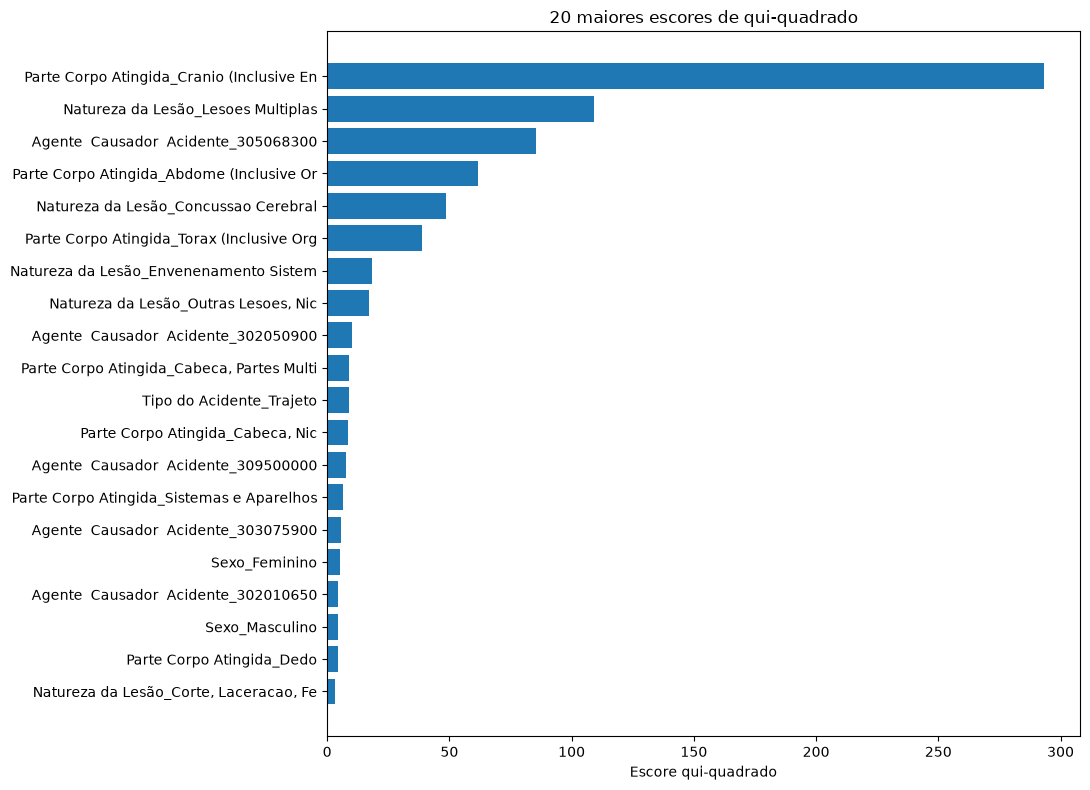

In [25]:
# Mostramos os 20 primeiros para manter os nomes legíveis.
ordem = res_chi2.head(20).sort_values("chi2_score")

plt.figure(figsize=(11, 8))
plt.barh(ordem["indicador"], ordem["chi2_score"])
plt.xlabel("Escore qui-quadrado")
plt.title("20 maiores escores de qui-quadrado")
plt.tight_layout()
plt.show()

## 14. Informação mútua

A informação mútua mede a dependência entre cada indicador e o alvo. Valores maiores representam maior dependência estimada na amostra. Como o one-hot produz valores 0 e 1, usamos `discrete_features=True`.

O método seleciona os 50 maiores escores sobre a mesma base utilizada pelo qui-quadrado. Os valores são expressos em nats e sua escala difere da escala do qui-quadrado. A raridade da classe Sim também deve ser considerada na leitura de valores pequenos.

In [26]:
sel_mi = SelectKBest(
    score_func=lambda X_, y_: mutual_info_classif(
        X_,
        y_,
        discrete_features=True,
        random_state=42,
    ),
    k=k_filtros,
)

sel_mi.fit(X_train_base, y_treino)

res_mi = pd.DataFrame({
    "indicador": X_train_base.columns,
    "informacao_mutua": sel_mi.scores_,
    "selecionado": sel_mi.get_support(),
}).sort_values("informacao_mutua", ascending=False)

display(res_mi)

,indicador,informacao_mutua,selecionado
174,Parte Corpo Atingida_Cranio (Inclusive En,3.323981e-03,True
219,Natureza da Lesão_Lesoes Multiplas,2.563337e-03,True
198,Parte Corpo Atingida_Torax (Inclusive Org,9.642764e-04,True
221,"Natureza da Lesão_Outras Lesoes, Nic",9.518905e-04,True
227,Sexo_Masculino,9.418125e-04,True
...,...,...,...
114,Agente Causador Acidente_305040250,6.644253e-07,False
117,Agente Causador Acidente_305040650,6.644253e-07,False
118,Agente Causador Acidente_305040900,6.644253e-07,False
129,Agente Causador Acidente_305064600,6.644253e-07,False


### 14.1 Indicadores selecionados

Extraímos as colunas escolhidas e preparamos as matrizes correspondentes. A classificação das categorias por escore pode diferir entre os dois filtros.

In [27]:
selecionados_mi = res_mi.loc[
    res_mi["selecionado"], "indicador"
].tolist()

print("INDICADORES SELECIONADOS POR INFORMAÇÃO MÚTUA")

for linha in res_mi.loc[res_mi["selecionado"]].itertuples(index=False):
    print(f"{linha.indicador} — MI = {linha.informacao_mutua:.6f}")

X_train_mi = X_train_base[selecionados_mi].copy()
X_test_mi = X_test_base[selecionados_mi].copy()

INDICADORES SELECIONADOS POR INFORMAÇÃO MÚTUA
Parte Corpo Atingida_Cranio (Inclusive En — MI = 0.003324
Natureza da Lesão_Lesoes Multiplas — MI = 0.002563
Parte Corpo Atingida_Torax (Inclusive Org — MI = 0.000964
Natureza da Lesão_Outras Lesoes, Nic — MI = 0.000952
Sexo_Masculino — MI = 0.000942
Sexo_Feminino — MI = 0.000937
Parte Corpo Atingida_Abdome (Inclusive Or — MI = 0.000911
Tipo do Acidente_Trajeto — MI = 0.000832
Natureza da Lesão_Concussao Cerebral — MI = 0.000832
Parte Corpo Atingida_Dedo — MI = 0.000823
Agente  Causador  Acidente_305068300 — MI = 0.000640
Natureza da Lesão_Corte, Laceracao, Fe — MI = 0.000638
Tipo do Acidente_Típico — MI = 0.000460
Parte Corpo Atingida_Cabeca, Nic — MI = 0.000420
Natureza da Lesão_Contusao, Esmagament — MI = 0.000396
Natureza da Lesão_Distensao, Torcao — MI = 0.000386
Natureza da Lesão_Envenenamento Sistem — MI = 0.000366
Parte Corpo Atingida_Cabeca, Partes Multi — MI = 0.000362
Parte Corpo Atingida_Pe (Exceto Artelhos) — MI = 0.000358
Agen

### 14.2 Ranking e interpretação

O gráfico apresenta os 20 maiores escores de informação mútua. Na execução de referência, trajeto ocupa a primeira posição. Medicamento em geral e acidente típico também aparecem entre os primeiros indicadores.

A seleção univariada avalia cada coluna separadamente. A contribuição conjunta de vários indicadores será investigada pelo Wrapper e pela árvore.

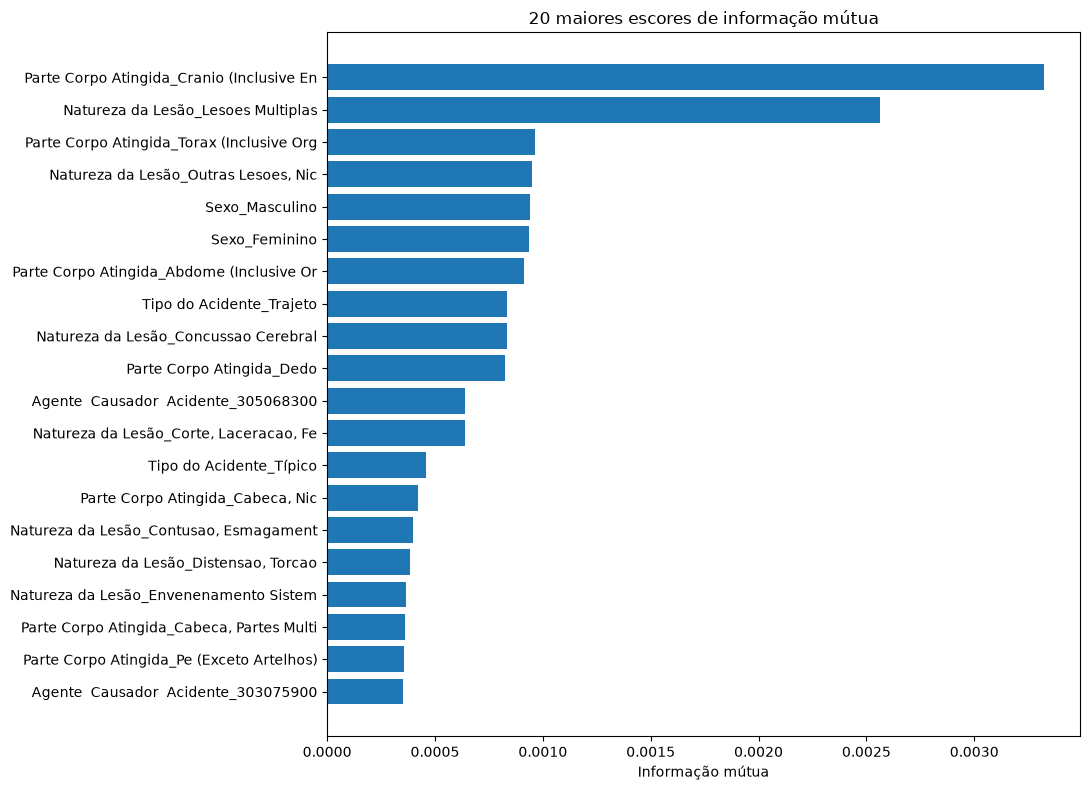

In [28]:
ordem = res_mi.head(20).sort_values("informacao_mutua")

plt.figure(figsize=(11, 8))
plt.barh(ordem["indicador"], ordem["informacao_mutua"])
plt.xlabel("Informação mútua")
plt.title("20 maiores escores de informação mútua")
plt.tight_layout()
plt.show()

## 15. Comparação e interseção dos filtros

Comparamos os conjuntos escolhidos pelo qui-quadrado e pela informação mútua, após a remoção de constantes. A listagem distingue os indicadores em comum e as escolhas exclusivas de cada método.

In [29]:
conjunto_chi2 = set(selecionados_chi2)
conjunto_mi = set(selecionados_mi)

print("EM COMUM")
for indicador in sorted(conjunto_chi2 & conjunto_mi):
    print("✓", indicador)

print("\nAPENAS NO QUI-QUADRADO")
for indicador in sorted(conjunto_chi2 - conjunto_mi):
    print("•", indicador)

print("\nAPENAS NA INFORMAÇÃO MÚTUA")
for indicador in sorted(conjunto_mi - conjunto_chi2):
    print("•", indicador)

EM COMUM
✓ Agente  Causador  Acidente_302010250
✓ Agente  Causador  Acidente_302010300
✓ Agente  Causador  Acidente_302010650
✓ Agente  Causador  Acidente_302050900
✓ Agente  Causador  Acidente_303010120
✓ Agente  Causador  Acidente_303075200
✓ Agente  Causador  Acidente_303075250
✓ Agente  Causador  Acidente_303075900
✓ Agente  Causador  Acidente_305068300
✓ Agente  Causador  Acidente_306060000
✓ Agente  Causador  Acidente_309500000
✓ Natureza da Lesão_Concussao Cerebral
✓ Natureza da Lesão_Contusao, Esmagament
✓ Natureza da Lesão_Corte, Laceracao, Fe
✓ Natureza da Lesão_Distensao, Torcao
✓ Natureza da Lesão_Envenenamento Sistem
✓ Natureza da Lesão_Escoriacao, Abrasao
✓ Natureza da Lesão_Fratura
✓ Natureza da Lesão_Lesoes Multiplas
✓ Natureza da Lesão_Luxacao
✓ Natureza da Lesão_Outras Lesoes, Nic
✓ Natureza da Lesão_Queimadura ou Escald
✓ Parte Corpo Atingida_Abdome (Inclusive Or
✓ Parte Corpo Atingida_Articulacao do Torno
✓ Parte Corpo Atingida_Cabeca, Nic
✓ Parte Corpo Atingida_Cab

### 15.1 Representação pela interseção

Mantemos uma coluna nessa representação quando ela passa pelos três critérios. A interseção constitui uma representação adicional para o experimento. Wrapper, árvore e PCA continuam partindo da base comum produzida pelo filtro de variância.

In [30]:
comparacao_filtros = pd.DataFrame({
    "variancia": nomes_indicadores.isin(mantidos_var),
    "qui_quadrado": nomes_indicadores.isin(selecionados_chi2),
    "informacao_mutua": nomes_indicadores.isin(selecionados_mi),
}, index=nomes_indicadores)

manter_intersecao = comparacao_filtros.all(axis=1)

selecionados_intersecao = comparacao_filtros.index[
    manter_intersecao
].tolist()

display(comparacao_filtros.assign(mantido=manter_intersecao))

X_train_intersecao = X_train_num[selecionados_intersecao].copy()
X_test_intersecao = X_test_num[selecionados_intersecao].copy()

print("Indicadores na interseção", len(selecionados_intersecao))

,variancia,qui_quadrado,informacao_mutua,mantido
indicador,,,,
Tipo do Acidente_Doença,True,True,True,True
Tipo do Acidente_Trajeto,True,True,True,True
Tipo do Acidente_Típico,True,True,True,True
Agente Causador Acidente_302010200,True,True,False,False
Agente Causador Acidente_302010250,True,True,True,True
...,...,...,...,...
Natureza da Lesão_Queimadura Quimica (,True,False,False,False
Natureza da Lesão_Queimadura ou Escald,True,True,True,True
Sexo_Feminino,True,True,True,True


Indicadores na interseção 47


A interseção reúne os indicadores selecionados simultaneamente pelo qui-quadrado e pela informação mútua, produzindo um conjunto consensual entre os dois critérios estatísticos.

# Parte II — Método Wrapper

## 16. Seleção sequencial forward

O método começa com um conjunto vazio e adiciona, a cada etapa, o indicador que produz a melhor avaliação interna em conjunto com os já selecionados. Uma árvore com profundidade máxima 4 funciona como avaliador.

Usamos três partições estratificadas e `average_precision`, com Sim como classe positiva. Os pesos de classe balanceados aumentam a participação relativa da classe rara no ajuste da árvore. O procedimento termina ao selecionar 8 indicadores, conforme o parâmetro definido.

A validação interna orienta a busca do subconjunto. Uma estimativa de desempenho para apresentação final precisa de avaliação externa a essa busca.

In [31]:
avaliador = DecisionTreeClassifier(
    max_depth=4,
    class_weight="balanced",
    random_state=42,
)

cv_wrapper = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42,
)

wrapper = SequentialFeatureSelector(
    avaliador,
    n_features_to_select=k_wrapper,
    direction="forward",
    scoring="average_precision",
    cv=cv_wrapper,
    n_jobs=-1,
)

wrapper.fit(X_train_base, y_treino)

selecionados_wrapper = X_train_base.columns[
    wrapper.get_support()
].tolist()

print("INDICADORES SELECIONADOS PELO WRAPPER")

for numero, indicador in enumerate(selecionados_wrapper, start=1):
    print(f"{numero}. {indicador}")

X_train_wrapper = X_train_base[selecionados_wrapper].copy()
X_test_wrapper = X_test_base[selecionados_wrapper].copy()

INDICADORES SELECIONADOS PELO WRAPPER
1. Tipo do Acidente_Doença
2. Agente  Causador  Acidente_303075200
3. Parte Corpo Atingida_Cabeca, Nic
4. Parte Corpo Atingida_Cabeca, Partes Multi
5. Parte Corpo Atingida_Cranio (Inclusive En
6. Parte Corpo Atingida_Torax (Inclusive Org
7. Natureza da Lesão_Contusao, Esmagament
8. Sexo_Masculino


Na execução de referência, o Wrapper selecionou os três tipos de acidente e cinco indicadores de agente causador — rua/estrada, calçada, escada permanente, chão e agente do acidente inexistente.

A presença de indicadores pouco destacados nos rankings individuais pode decorrer de sua contribuição em conjunto com as colunas já escolhidas. A quantidade de 8 corresponde ao limite configurado.

# Parte III — Método embutido

## 17. Seleção pela importância da árvore

A árvore é ajustada sobre a base após o filtro de variância. As importâncias representam a participação dos indicadores na redução da impureza obtida pelas divisões da árvore.

Usamos profundidade máxima 5, pesos de classe balanceados e pelo menos 8 registros em cada folha. Esse mínimo pode limitar o uso de categorias muito raras. Serão selecionados os indicadores com importância maior que zero.

In [32]:
arvore = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=8,
    class_weight="balanced",
    random_state=42,
)

arvore.fit(X_train_base, y_treino)

importancias = pd.DataFrame({
    "indicador": X_train_base.columns,
    "importancia": arvore.feature_importances_,
}).sort_values(
    ["importancia", "indicador"],
    ascending=[False, True],
)

display(importancias)

,indicador,importancia
174,Parte Corpo Atingida_Cranio (Inclusive En,0.254958
219,Natureza da Lesão_Lesoes Multiplas,0.235535
221,"Natureza da Lesão_Outras Lesoes, Nic",0.210013
217,Natureza da Lesão_Lesao Imediata,0.101308
227,Sexo_Masculino,0.090358
...,...,...
199,"Parte Corpo Atingida_Tronco, Nic",0.000000
200,"Parte Corpo Atingida_Tronco, Parte Multip",0.000000
226,Sexo_Indeterminado,0.000000
1,Tipo do Acidente_Trajeto,0.000000


### 17.1 Indicadores utilizados

A lista apresenta os indicadores efetivamente utilizados por esta árvore. A importância depende dos dados, dos parâmetros e das demais colunas disponíveis.

In [33]:
imp_positivas = importancias.loc[
    importancias["importancia"] > 0
].copy()

selecionados_embutido = imp_positivas["indicador"].tolist()

print("INDICADORES UTILIZADOS PELA ÁRVORE")

for linha in imp_positivas.itertuples(index=False):
    print(f"{linha.indicador} — importância = {linha.importancia:.6f}")

X_train_embutido = X_train_base[selecionados_embutido].copy()
X_test_embutido = X_test_base[selecionados_embutido].copy()

INDICADORES UTILIZADOS PELA ÁRVORE
Parte Corpo Atingida_Cranio (Inclusive En — importância = 0.254958
Natureza da Lesão_Lesoes Multiplas — importância = 0.235535
Natureza da Lesão_Outras Lesoes, Nic — importância = 0.210013
Natureza da Lesão_Lesao Imediata — importância = 0.101308
Sexo_Masculino — importância = 0.090358
Natureza da Lesão_Envenenamento Sistem — importância = 0.082504
Tipo do Acidente_Doença — importância = 0.008603
Agente  Causador  Acidente_303075200 — importância = 0.008271
Agente  Causador  Acidente_Desconhecido — importância = 0.007521
Parte Corpo Atingida_Partes Multiplas - A — importância = 0.000678
Sexo_Feminino — importância = 0.000252


Os indicadores selecionados pela árvore de decisão refletem as combinações de parte do corpo atingida, natureza da lesão, tipo de acidente, agente causador e sexo que mais reduzem a impureza ponderada no treino.

# Parte IV — Comparação das seleções

## 18. Concordância entre os métodos

A tabela marca a escolha de cada indicador pelos quatro métodos e soma quantos deles o selecionaram. Os métodos usam critérios diferentes e quantidades de colunas diferentes.

Na execução de referência, trajeto, típico, calçada e agente do acidente inexistente foram escolhidos pelos quatro métodos. A concordância auxilia a discussão dos resultados, enquanto a utilidade preditiva será medida na validação.

In [34]:
selecoes = {
    "Qui-quadrado": selecionados_chi2,
    "Informação mútua": selecionados_mi,
    "Wrapper": selecionados_wrapper,
    "Embutido": selecionados_embutido,
}

comparacao = pd.DataFrame(
    {
        metodo: X_train_base.columns.isin(indicadores)
        for metodo, indicadores in selecoes.items()
    },
    index=X_train_base.columns,
)

comparacao.index.name = "indicador"
comparacao["quantidade_metodos"] = comparacao.sum(axis=1)

comparacao = comparacao.sort_values(
    "quantidade_metodos",
    ascending=False,
)

with pd.option_context("display.max_rows", None):
    display(comparacao)

,Qui-quadrado,Informação mútua,Wrapper,Embutido,quantidade_metodos
indicador,,,,,
Tipo do Acidente_Doença,True,True,True,True,4
Agente Causador Acidente_303075200,True,True,True,True,4
Parte Corpo Atingida_Cranio (Inclusive En,True,True,True,True,4
Sexo_Masculino,True,True,True,True,4
"Natureza da Lesão_Contusao, Esmagament",True,True,True,False,3
Natureza da Lesão_Envenenamento Sistem,True,True,False,True,3
"Parte Corpo Atingida_Cabeca, Partes Multi",True,True,True,False,3
"Parte Corpo Atingida_Cabeca, Nic",True,True,True,False,3
Parte Corpo Atingida_Torax (Inclusive Org,True,True,True,False,3


# Parte V — Extração de características com PCA

## 19. Componentes principais

O PCA cria novas colunas por meio de combinações lineares dos indicadores. Cada componente descreve uma direção de variação dos dados. O alvo será usado na visualização para identificar os registros com óbito.

### 19.1 Padronização

Seguindo o procedimento da aula, subtraímos a média de cada indicador e dividimos pelo desvio-padrão calculado no treino. A mesma transformação é aplicada ao teste.

Nos indicadores binários, essa padronização aumenta o peso relativo das categorias raras. O comportamento do PCA depende dessa escolha de escala.

In [35]:
scaler = StandardScaler()

X_train_std = scaler.fit_transform(X_train_base)
X_test_std = scaler.transform(X_test_base)

print("Indicadores que entram no PCA", X_train_base.shape[1])

print(
    "Média absoluta das médias após padronização",
    np.abs(X_train_std.mean(axis=0)).mean().round(6),
)

print(
    "Desvio-padrão médio após padronização",
    X_train_std.std(axis=0).mean().round(6),
)

Indicadores que entram no PCA 228
Média absoluta das médias após padronização 0.0
Desvio-padrão médio após padronização 1.0


### 19.2 PCA completo

Ajustamos inicialmente todas as componentes disponíveis. `variancia_explicada` mostra a contribuição individual de cada componente e `variancia_acumulada` soma as contribuições até aquela posição.

In [36]:
pca_all = PCA(svd_solver="full")
pca_all.fit(X_train_std)

var_explicada = pca_all.explained_variance_ratio_
var_acumulada = np.cumsum(var_explicada)

tab_pca = pd.DataFrame({
    "componente": [
        f"CP{i + 1}" for i in range(len(var_explicada))
    ],
    "variancia_explicada": var_explicada,
    "variancia_acumulada": var_acumulada,
})

display(tab_pca)

,componente,variancia_explicada,variancia_acumulada
0,CP1,1.459735e-02,0.014597
1,CP2,1.393653e-02,0.028534
2,CP3,1.078918e-02,0.039323
3,CP4,8.464969e-03,0.047788
4,CP5,8.361717e-03,0.056150
...,...,...,...
223,CP224,3.816166e-32,1.000000
224,CP225,7.144350e-33,1.000000
225,CP226,4.318292e-33,1.000000
226,CP227,3.500689e-33,1.000000


### 19.3 Scree plot

O gráfico apresenta a variância explicada por componente. Uma concentração nas primeiras componentes permitiria representar grande parte da variação com poucas colunas.

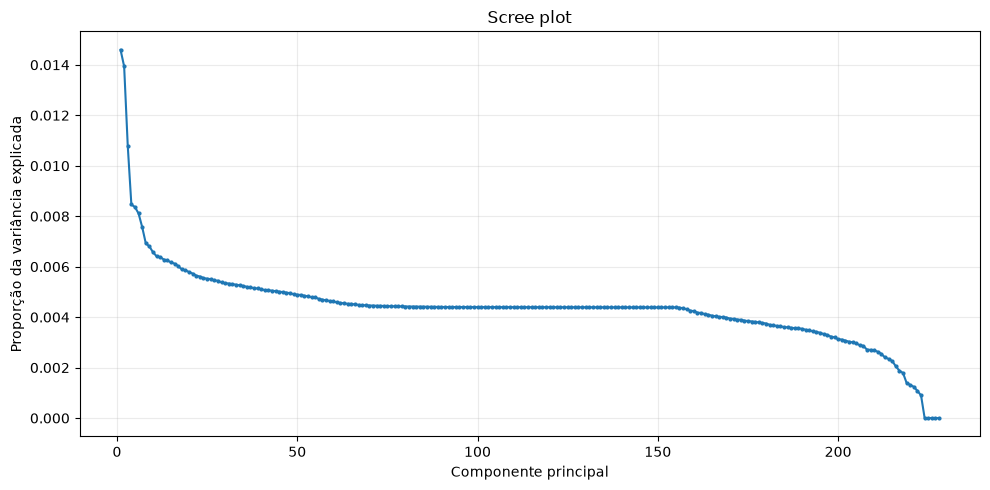

In [37]:
numeros_componentes = np.arange(1, len(var_explicada) + 1)

plt.figure(figsize=(10, 5))
plt.plot(
    numeros_componentes,
    var_explicada,
    marker=".",
    markersize=4,
)
plt.xlabel("Componente principal")
plt.ylabel("Proporção da variância explicada")
plt.title("Scree plot")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 19.4 Variância explicada acumulada

Identificamos quantas componentes são necessárias para preservar pelo menos 85%, 90% e 95% da variância da matriz padronizada.

Na execução de referência, esses limites exigiram respectivamente 134, 142 e 150 componentes. A variação está distribuída por muitas direções.

Componentes para pelo menos 85% — 173
Componentes para pelo menos 90% — 187
Componentes para pelo menos 95% — 201


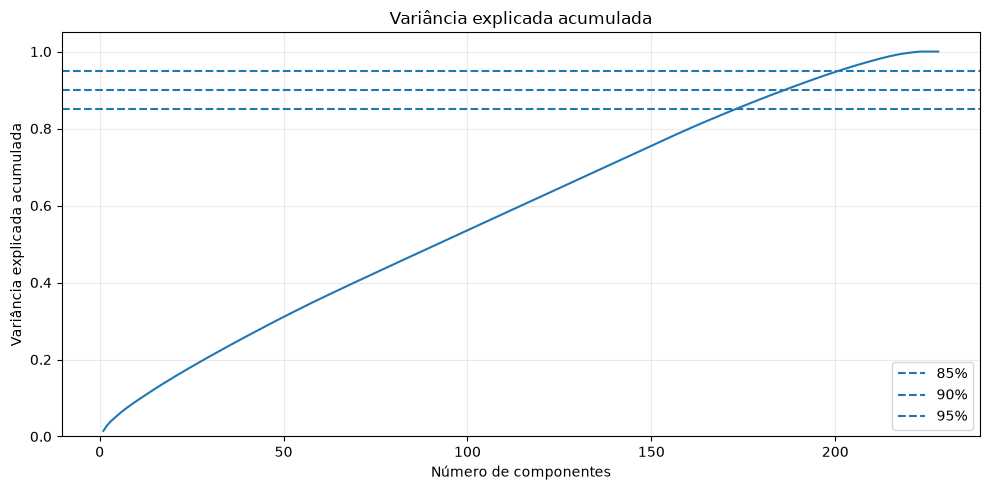

In [38]:
plt.figure(figsize=(10, 5))
plt.plot(numeros_componentes, var_acumulada)

for meta in [0.85, 0.90, 0.95]:
    plt.axhline(
        meta,
        linestyle="--",
        label=f"{meta:.0%}",
    )

    quantidade = int(np.searchsorted(var_acumulada, meta) + 1)
    print(f"Componentes para pelo menos {meta:.0%} — {quantidade}")

plt.xlabel("Número de componentes")
plt.ylabel("Variância explicada acumulada")
plt.title("Variância explicada acumulada")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 19.5 Representação com 90% da variância

Escolhemos 90% como parâmetro de retenção, seguindo o exemplo da aula. O PCA determina a quantidade de componentes a partir do treino e aplica a transformação ao teste.

In [39]:
pca_90 = PCA(
    n_components=0.90,
    svd_solver="full",
)

X_train_pca90 = pca_90.fit_transform(X_train_std)
X_test_pca90 = pca_90.transform(X_test_std)

print("Dimensionalidade antes do PCA", X_train_base.shape[1])
print("Dimensionalidade após PCA", pca_90.n_components_)

print(
    "Variância preservada",
    f"{pca_90.explained_variance_ratio_.sum():.2%}",
)

Dimensionalidade antes do PCA 228
Dimensionalidade após PCA 187
Variância preservada 90.31%


A retenção de 90% da variância padronizada indica o quanto a informação está distribuída entre muitos indicadores binários raros: quando a maior parte das categorias ocorre em poucos registros, o PCA precisa manter grande parte das componentes para preservar 90% da variância.

### 19.6 Pesos das componentes

Cada coluna da tabela corresponde a uma componente e cada linha corresponde a um indicador. O valor de uma célula é o coeficiente daquele indicador padronizado na combinação linear.

Os coeficientes com maior módulo ajudam a interpretar quais indicadores mais participam da componente. O sinal indica a direção da contribuição na orientação produzida pelo ajuste.

In [40]:
nomes_cp = [
    f"CP{i + 1}" for i in range(pca_90.n_components_)
]

pesos_pca = pd.DataFrame(
    pca_90.components_.T,
    index=X_train_base.columns,
    columns=nomes_cp,
)

display(pesos_pca)

,CP1,CP2,CP3,CP4,CP5,CP6,CP7,CP8,CP9,CP10,...,CP178,CP179,CP180,CP181,CP182,CP183,CP184,CP185,CP186,CP187
indicador,,,,,,,,,,,,,,,,,,,,,
Tipo do Acidente_Doença,0.444075,-0.208285,-0.112303,0.068546,-0.042806,-0.010284,0.032244,0.007321,0.005817,-0.051010,...,-0.006501,-0.019116,0.004912,-0.006130,-0.003000,0.008532,0.005824,-0.033046,-0.015928,0.010851
Tipo do Acidente_Trajeto,0.143893,0.435050,0.057919,-0.265868,-0.067820,-0.067923,0.080080,0.082314,-0.015065,0.034665,...,-0.011100,0.028627,0.007246,-0.034658,-0.012764,0.004473,0.022255,0.002328,0.019060,-0.001612
Tipo do Acidente_Típico,-0.378503,-0.285996,0.008734,0.207289,0.086247,0.068341,-0.091709,-0.079975,0.010675,-0.003742,...,0.013836,-0.015825,-0.009402,0.035360,0.013433,-0.008848,-0.023751,0.016143,-0.008764,-0.004519
Agente Causador Acidente_302010200,0.042734,0.160333,0.021272,-0.063507,-0.023255,-0.020923,0.031903,0.055787,-0.003272,-0.007414,...,-0.008234,0.012433,-0.003111,-0.000618,-0.049778,0.047360,-0.043551,-0.055869,0.044190,-0.000995
Agente Causador Acidente_302010250,0.016166,0.074308,0.118971,0.028796,-0.073307,-0.075487,0.069569,0.093176,-0.023769,-0.001551,...,0.077496,-0.060498,0.014522,0.098011,0.072844,-0.032525,0.065197,0.012417,-0.039652,0.084788
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Natureza da Lesão_Queimadura Quimica (,-0.006387,-0.036703,0.032175,-0.037094,0.125535,0.083186,-0.176691,0.229163,-0.246655,0.159543,...,0.028584,0.048997,0.003705,0.004196,-0.032485,0.020219,-0.048680,0.026918,-0.018943,-0.013142
Natureza da Lesão_Queimadura ou Escald,-0.038815,-0.058960,0.077109,-0.002190,0.234593,0.437664,0.375746,0.094389,0.008682,-0.057323,...,0.000707,0.002304,-0.003809,-0.030996,0.024178,-0.008238,-0.002201,-0.013615,0.006248,0.030070
Sexo_Feminino,0.038830,-0.220065,0.481123,-0.209858,-0.088815,-0.086668,0.106680,-0.037736,0.066098,0.066740,...,0.027919,-0.049257,-0.004139,0.005516,-0.079176,-0.009203,-0.017316,0.038589,0.028556,-0.041500


### 19.7 Combinações lineares

Uma componente pode ser escrita como

\[
CP_j = \sum_{i=1}^{p} a_{ji} Z_i
\]

Os termos \(Z_i\) representam os indicadores padronizados e centrados pelo PCA. Os coeficientes \(a_{ji}\) são obtidos de `pca_90.components_`. A célula seguinte imprime uma equação por componente mantida.

In [41]:
def imprimir_equacao(numero, componentes, indicadores):
    pesos = componentes[numero - 1]

    termos = [
        f"{peso:+.4f} × Z[{indicador}]"
        for peso, indicador in zip(pesos, indicadores)
    ]

    print(f"CP{numero} = " + " ".join(termos))


# Uma equação completa para cada componente mantida.
for numero in range(1, pca_90.n_components_ + 1):
    imprimir_equacao(
        numero,
        pca_90.components_,
        X_train_base.columns,
    )
    print()

CP1 = +0.4441 × Z[Tipo do Acidente_Doença] +0.1439 × Z[Tipo do Acidente_Trajeto] -0.3785 × Z[Tipo do Acidente_Típico] +0.0427 × Z[Agente  Causador  Acidente_302010200] +0.0162 × Z[Agente  Causador  Acidente_302010250] -0.0308 × Z[Agente  Causador  Acidente_302010300] -0.0319 × Z[Agente  Causador  Acidente_302010350] -0.0068 × Z[Agente  Causador  Acidente_302010400] -0.0004 × Z[Agente  Causador  Acidente_302010450] -0.0040 × Z[Agente  Causador  Acidente_302010500] -0.0273 × Z[Agente  Causador  Acidente_302010550] -0.0099 × Z[Agente  Causador  Acidente_302010600] +0.0025 × Z[Agente  Causador  Acidente_302010650] -0.0145 × Z[Agente  Causador  Acidente_302010700] +0.0005 × Z[Agente  Causador  Acidente_302010900] -0.0208 × Z[Agente  Causador  Acidente_302030900] +0.0080 × Z[Agente  Causador  Acidente_302050100] +0.0029 × Z[Agente  Causador  Acidente_302050200] -0.0006 × Z[Agente  Causador  Acidente_302050300] +0.0049 × Z[Agente  Causador  Acidente_302050500] -0.0035 × Z[Agente  Causador  Ac

CP115 = -0.0015 × Z[Tipo do Acidente_Doença] -0.0003 × Z[Tipo do Acidente_Trajeto] +0.0011 × Z[Tipo do Acidente_Típico] +0.0021 × Z[Agente  Causador  Acidente_302010200] +0.0144 × Z[Agente  Causador  Acidente_302010250] +0.0027 × Z[Agente  Causador  Acidente_302010300] +0.0066 × Z[Agente  Causador  Acidente_302010350] +0.0053 × Z[Agente  Causador  Acidente_302010400] -0.0310 × Z[Agente  Causador  Acidente_302010450] -0.1237 × Z[Agente  Causador  Acidente_302010500] -0.0020 × Z[Agente  Causador  Acidente_302010550] +0.0000 × Z[Agente  Causador  Acidente_302010600] -0.0025 × Z[Agente  Causador  Acidente_302010650] -0.0390 × Z[Agente  Causador  Acidente_302010700] +0.0024 × Z[Agente  Causador  Acidente_302010900] +0.0039 × Z[Agente  Causador  Acidente_302030900] +0.0042 × Z[Agente  Causador  Acidente_302050100] -0.0405 × Z[Agente  Causador  Acidente_302050200] -0.0274 × Z[Agente  Causador  Acidente_302050300] -0.0606 × Z[Agente  Causador  Acidente_302050500] +0.0687 × Z[Agente  Causador  

### 19.8 Maiores coeficientes por componente

A inspeção dos cinco maiores pesos absolutos por componente principal ajuda a interpretar quais combinações de tipo de acidente, parte do corpo, lesão, agente e sexo mais contribuem para cada direção de variância.

In [42]:
for componente in nomes_cp:
    maiores = (
        pesos_pca[componente]
        .abs()
        .sort_values(ascending=False)
        .head(5)
    )

    print(f"Cinco maiores pesos em {componente}")

    for indicador in maiores.index:
        peso = pesos_pca.loc[indicador, componente]
        print(f"  {indicador} — {peso:+.4f}")

    print()

Cinco maiores pesos em CP1
  Tipo do Acidente_Doença — +0.4441
  Natureza da Lesão_Doenca, Nic — +0.3966
  Parte Corpo Atingida_Sistema Nervoso — +0.3819
  Tipo do Acidente_Típico — -0.3785
  Agente  Causador  Acidente_Desconhecido — +0.3340

Cinco maiores pesos em CP2
  Tipo do Acidente_Trajeto — +0.4351
  Tipo do Acidente_Típico — -0.2860
  Agente  Causador  Acidente_303075200 — +0.2248
  Sexo_Masculino — +0.2211
  Sexo_Feminino — -0.2201

Cinco maiores pesos em CP3
  Sexo_Feminino — +0.4811
  Sexo_Masculino — -0.4798
  Natureza da Lesão_Corte, Laceracao, Fe — -0.2540
  Natureza da Lesão_Distensao, Torcao — +0.2394
  Agente  Causador  Acidente_302010350 — +0.2075

Cinco maiores pesos em CP4
  Natureza da Lesão_Distensao, Torcao — +0.3259
  Tipo do Acidente_Trajeto — -0.2659
  Parte Corpo Atingida_Articulacao do Torno — +0.2483
  Parte Corpo Atingida_Pe (Exceto Artelhos) — +0.2162
  Agente  Causador  Acidente_302010350 — +0.2122

Cinco maiores pesos em CP5
  Parte Corpo Atingida_Apare

Cinco maiores pesos em CP129
  Agente  Causador  Acidente_303020760 — +0.4006
  Agente  Causador  Acidente_303010280 — -0.3111
  Agente  Causador  Acidente_303015050 — -0.2394
  Agente  Causador  Acidente_305032000 — +0.2375
  Agente  Causador  Acidente_303010720 — +0.2265

Cinco maiores pesos em CP130
  Agente  Causador  Acidente_303015050 — +0.5219
  Agente  Causador  Acidente_303075600 — -0.3548
  Agente  Causador  Acidente_303035400 — -0.3129
  Agente  Causador  Acidente_303045200 — -0.2431
  Agente  Causador  Acidente_303010680 — +0.2400

Cinco maiores pesos em CP131
  Agente  Causador  Acidente_303045200 — +0.3778
  Agente  Causador  Acidente_303075650 — -0.2881
  Agente  Causador  Acidente_305048300 — -0.2654
  Agente  Causador  Acidente_303010280 — -0.2429
  Agente  Causador  Acidente_303020280 — -0.2145

Cinco maiores pesos em CP132
  Agente  Causador  Acidente_305060000 — +0.3996
  Agente  Causador  Acidente_306040000 — -0.2655
  Agente  Causador  Acidente_303015450 — +0.2571

### 19.9 Projeção em CP1 e CP2

O gráfico posiciona cada registro de treino nas duas primeiras componentes. Os registros com óbito são destacados por cruzes vermelhas.

Na execução de referência, esses dois eixos preservam somente 2,92% da variância padronizada. Há sobreposição visual entre as classes nessa projeção. A pequena fração de variância representada limita as conclusões que podem ser extraídas do desenho bidimensional.

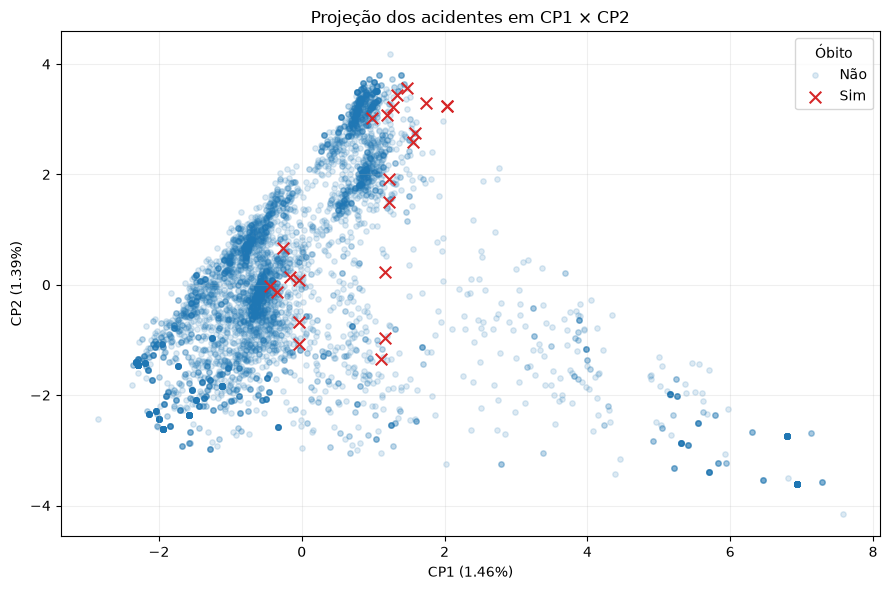

Variância preservada por CP1 e CP2 2.85%


In [43]:
# Reutilizamos as duas primeiras componentes do PCA completo.
X_train_pca2 = pca_all.transform(X_train_std)[:, :2]
teve_obito = y_treino.to_numpy() == 1

plt.figure(figsize=(9, 6))

plt.scatter(
    X_train_pca2[~teve_obito, 0],
    X_train_pca2[~teve_obito, 1],
    label="Não",
    color="tab:blue",
    alpha=0.15,
    s=15,
)

plt.scatter(
    X_train_pca2[teve_obito, 0],
    X_train_pca2[teve_obito, 1],
    label="Sim",
    color="tab:red",
    marker="x",
    s=70,
    linewidths=1.5,
    zorder=3,
)

plt.xlabel(f"CP1 ({var_explicada[0]:.2%})")
plt.ylabel(f"CP2 ({var_explicada[1]:.2%})")
plt.title("Projeção dos acidentes em CP1 × CP2")
plt.legend(title="Óbito")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    "Variância preservada por CP1 e CP2",
    f"{var_explicada[:2].sum():.2%}",
)

## 20. Síntese das representações

A tabela final compara a quantidade de colunas produzida por cada técnica. Na seleção, cada coluna mantém o significado de um indicador do one-hot. No PCA, cada coluna representa uma combinação linear de indicadores padronizados.

In [44]:
dimensoes = pd.DataFrame({
    "representacao": [
        "One-hot completo",
        "Após variância",
        "Qui-quadrado",
        "Informação mútua",
        "Interseção dos filtros",
        "Wrapper",
        "Embutido",
        "PCA com 90%",
    ],
    "quantidade_colunas": [
        X_train_num.shape[1],
        X_train_base.shape[1],
        X_train_chi2.shape[1],
        X_train_mi.shape[1],
        X_train_intersecao.shape[1],
        X_train_wrapper.shape[1],
        X_train_embutido.shape[1],
        X_train_pca90.shape[1],
    ],
})

display(dimensoes)

,representacao,quantidade_colunas
0,One-hot completo,228
1,Após variância,228
2,Qui-quadrado,50
3,Informação mútua,50
4,Interseção dos filtros,47
5,Wrapper,8
6,Embutido,11
7,PCA com 90%,187


### 20.1 Resultados e limites da interpretação

Na execução de referência, a base com 228 indicadores (a partir das cinco entradas de triagem) gerou representações com 50 colunas pelo qui-quadrado, 50 pela informação mútua, 47 pela interseção, 8 pelo Wrapper, 11 pela árvore e 187 pelo PCA com retenção de 90,31% da variância. O filtro de variância zero manteve os 228 indicadores.

Os resultados permitem observar a concordância entre as seleções e a redução de dimensão obtida. Indicadores ligados a lesões graves e regiões vitais (como crânio, lesões múltiplas e acidentes de trajeto) aparecem entre os destacados pelos diferentes métodos. Categorias com poucos registros exigem atenção ao suporte das associações observadas. A atribuição de causalidade exige um desenho de investigação específico.

A avaliação comparável de desempenho deve usar as mesmas partições e o mesmo classificador para cada representação, reajustando one-hot, seleção, padronização e PCA dentro do treino de cada fold. Average precision e recall de Sim orientam essa avaliação. A amostra contém apenas 22 óbitos no treino e 5 no teste, de modo que poucos casos têm grande impacto nas métricas.

As interpretações deste notebook se referem ao recorte de CATs, às cinco entradas de triagem escolhidas, à divisão aleatória estratificada e aos parâmetros registrados no código.

## 21. Exportação das bases de treino e teste

Salvamos as bases já limpas e divididas em `datasets/processados/treino.csv` e `datasets/processados/teste.csv` para reutilização direta na etapa de modelagem (`03_modelos_supervisionados.ipynb`).

Exportamos as cinco entradas categóricas de triagem tratadas (`X_train_cat` e `X_test_cat`) acompanhadas do alvo `Indica Óbito Acidente`, **antes** da codificação *one-hot*. Isso garante que o notebook seguinte utilize exatamente a mesma divisão estratificada (80% treino / 20% teste, `random_state=42`) e possa ajustar o `OneHotEncoder` e os redutores separadamente dentro de cada fold da validação cruzada, sem vazamento de dados.

In [45]:
pasta_saida = Path("datasets/processados")
pasta_saida.mkdir(parents=True, exist_ok=True)

df_treino_saida = X_train_cat.copy()
df_treino_saida["Indica Óbito Acidente"] = y_train.loc[X_train_cat.index]

df_teste_saida = X_test_cat.copy()
df_teste_saida["Indica Óbito Acidente"] = y_test.loc[X_test_cat.index]

caminho_treino = pasta_saida / "treino.csv"
caminho_teste = pasta_saida / "teste.csv"

df_treino_saida.to_csv(caminho_treino, index=False, encoding="utf-8")
df_teste_saida.to_csv(caminho_teste, index=False, encoding="utf-8")

print(f"Treino salvo em {caminho_treino}: {df_treino_saida.shape}")
print(f"Teste salvo em {caminho_teste}: {df_teste_saida.shape}")
display(df_treino_saida.head())

Treino salvo em datasets/processados/treino.csv: (5760, 6)
Teste salvo em datasets/processados/teste.csv: (1441, 6)


,Tipo do Acidente,Agente Causador Acidente,Parte Corpo Atingida,Natureza da Lesão,Sexo,Indica Óbito Acidente
6547,Típico,309000000,Mao (Exceto Punho ou,Lesao Imediata,Masculino,Não
4604,Trajeto,302010200,"Membros Superiores,",Fratura,Masculino,Não
1232,Típico,305028000,Perna (Entre O Torno,"Contusao, Esmagament",Feminino,Não
6003,Típico,305032500,Pe (Exceto Artelhos),Fratura,Masculino,Não
1869,Típico,302010350,Pe (Exceto Artelhos),"Distensao, Torcao",Feminino,Não


## 22. Referências dos métodos

As definições e os parâmetros utilizados podem ser consultados na documentação do scikit-learn. [Seleção de características](https://scikit-learn.org/stable/modules/feature_selection.html), [informação mútua](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.mutual_info_classif.html) e [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).